# Basic usage foe ERA5 data

In this example, we demonstrate the basic usage for a snapshot of ERA5 data. This is essentially a replication of the basic usage example for the lifecycle benchmark. The only difference, apart from the input data, is the choice of minimum pressure `pmin`, which here is 1 Pascal since the isentropic levels go up to around 3000K, and the choice of smoothing parameter `eps`, set here to be `5e-3` which we have found to give good results.

We import `atmosphere_bgs` and prepare the input data.

In [ ]:
import atmosphere_bgs

year = '2010'
month = '01'
day = '22'
dtime = '18'
path = '../../input_data/mass_circ_era5_'+year+month+day+dtime+'.nc'
input_data = atmosphere_bgs.DataLoader(path,pmin=1)

We solve the semi-discrete optimal transport problem.

In [5]:
solv = atmosphere_bgs.OTSolver(input_data)
ld, duals = solv.get_bgs(verbose=True)

initial duals calculated
try to fix 0 bad areas
it=-1, lr=1.00e-05, good_areas=10869/10869
it=0, lr=2.00e-05, good_areas=10869/10869, meanerr=4.226732e+02, l2err = 3.785264e+06, max_err=3.724948e+06
it=1, lr=4.00e-05, good_areas=10869/10869, meanerr=4.226602e+02, l2err = 3.785153e+06, max_err=3.724839e+06
it=2, lr=8.00e-05, good_areas=10869/10869, meanerr=4.226343e+02, l2err = 3.784930e+06, max_err=3.724623e+06
it=3, lr=1.60e-04, good_areas=10869/10869, meanerr=4.225823e+02, l2err = 3.784484e+06, max_err=3.724189e+06
it=4, lr=3.20e-04, good_areas=10869/10869, meanerr=4.224783e+02, l2err = 3.783592e+06, max_err=3.723321e+06
it=5, lr=6.40e-04, good_areas=10869/10869, meanerr=4.222714e+02, l2err = 3.781808e+06, max_err=3.721585e+06
it=6, lr=1.28e-03, good_areas=10869/10869, meanerr=4.218766e+02, l2err = 3.778279e+06, max_err=3.718115e+06
it=7, lr=2.56e-03, good_areas=10869/10869, meanerr=4.210476e+02, l2err = 3.771147e+06, max_err=3.711177e+06
it=8, lr=5.12e-03, good_areas=10869/10869, me

We apply smoothing and interpolation to the MLM state.

In [6]:
# post process the MLM state
bscirc = input_data.bscirc
pvlevs = input_data.pvlevs
thlevs = input_data.thlevs
pvmaxth = input_data.data_dict['pvmaxth']
    
mlm = atmosphere_bgs.PostProcessor(solv,bscirc,pvlevs,thlevs,pvmaxth,eps=5e-3,res=[180,180],make_surface_adjustments=True)

# put the post-processed data into a dictionary
data_dict = atmosphere_bgs.data_io.get_mlm_data_dict(mlm)

# convert the dictionary to an xarray dataset and (optionally) save to netCDF
ds = atmosphere_bgs.data_io.save_bgs_to_netCDF(data_dict,file_path=None) # to save on a path specify file_path

fixed 111 intersects
No file path specified. Dataset generated in memory only.


Variables can be plotted using the inbuilt `xarray` plotting functions.

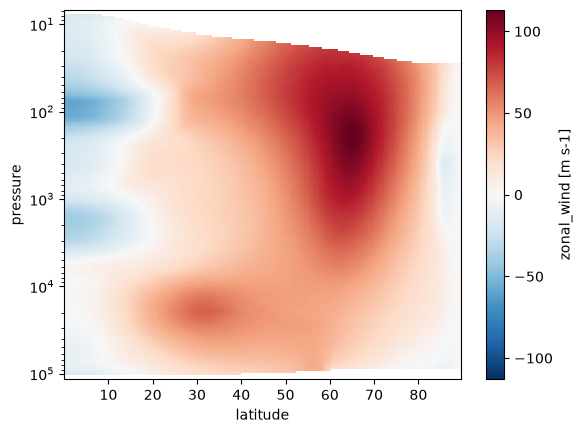

In [11]:
ds.zonal_wind.plot(x='latitude',y='pressure',yincrease=False,yscale='log') # zonal wind in pressure coordinates on log scale

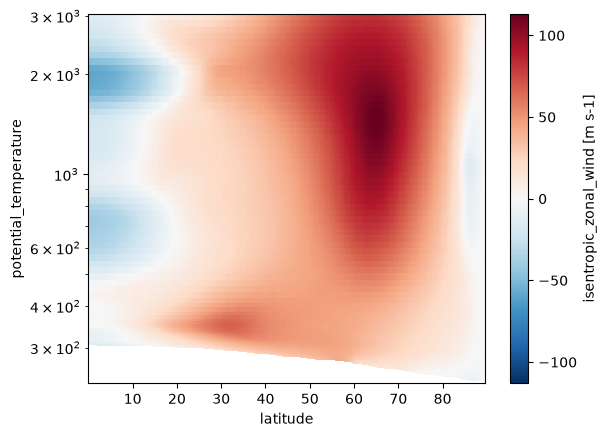

In [14]:
ds.isentropic_zonal_wind.plot(x='latitude',y='potential_temperature',yscale='log')

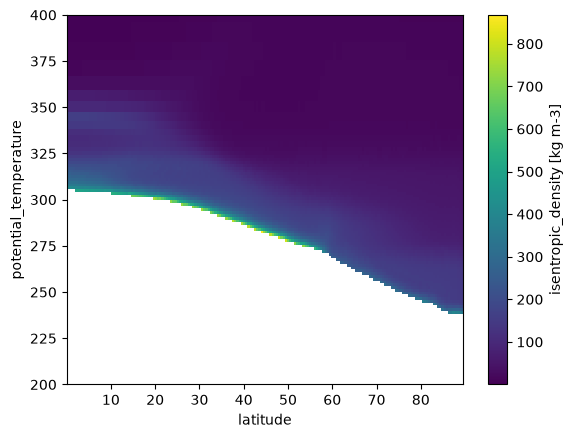

In [17]:
ds.isentropic_density.plot(x='latitude',y='potential_temperature',ylim=[200,400])

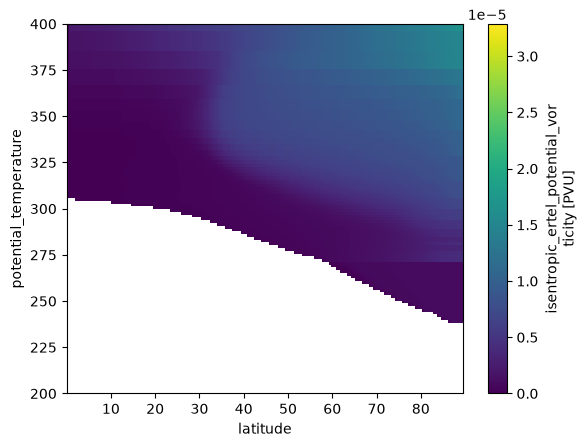

In [20]:
ds.isentropic_ertel_potential_vorticity.plot(x='latitude',y='potential_temperature',ylim=[200,400])